In [1]:
# ab86e3d18dea2b18ee36e69b
# https://v6.exchangerate-api.com/v6/ab86e3d18dea2b18ee36e69b/latest/USD

In [2]:
from langchain.tools import tool
import requests

@tool 
def get_conversion_factor(base_currency : str , target_currency: str) -> float :
    """This function fetches the currency conversion factor between a given base currency and a target currency"""

    url = f"https://v6.exchangerate-api.com/v6/ab86e3d18dea2b18ee36e69b/pair/{base_currency}/{target_currency}"

    response = requests.get(url)

    return response.json()


In [3]:
get_conversion_factor.invoke({"base_currency" : "USD" , "target_currency" : "INR"})

{'result': 'success',
 'documentation': 'https://www.exchangerate-api.com/docs',
 'terms_of_use': 'https://www.exchangerate-api.com/terms',
 'time_last_update_unix': 1759536002,
 'time_last_update_utc': 'Sat, 04 Oct 2025 00:00:02 +0000',
 'time_next_update_unix': 1759622402,
 'time_next_update_utc': 'Sun, 05 Oct 2025 00:00:02 +0000',
 'base_code': 'USD',
 'target_code': 'INR',
 'conversion_rate': 88.8022}

In [4]:
@tool
def convert(base_currency_value : int , conversion_rate : float) -> float :
    """given a currency conversion rate this function calculates the target currency value given the base currency value"""

    return base_currency_value * conversion_rate

In [5]:
convert.invoke({"base_currency_value" : 10 , "conversion_rate" : 88.80 })

888.0

In [6]:
# OUR BOTH TOOLS ARE READY FOR NOW , NOW LETS BIND THEM

In [7]:
from langchain_huggingface import ChatHuggingFace , HuggingFaceEndpoint
from dotenv import load_dotenv
from langchain_core.prompts import PromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain.schema.runnable import RunnableSequence
from langchain.tools import BaseTool 
from typing import Type
from pydantic import BaseModel , Field


load_dotenv()

llm = HuggingFaceEndpoint(
    # repo_id = "google/gemma-2-2b-it",
    repo_id="deepseek-ai/DeepSeek-R1-0528",
    # huggingfacehub_api_token="YOUR_HF_TOKEN",
    huggingfacehub_api_token="YOUR_HF_TOKEN",
    task = "text-generation"
)

model = ChatHuggingFace(llm = llm)


/home/swaraj/projects/langchain/tools/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
llm_with_tools = model.bind_tools([get_conversion_factor , convert])

In [9]:
from langchain_core.messages import HumanMessage
query = HumanMessage("What is the conversion rate between USD and INR , and based on that  convert 10 USD to INR")
message = [query]

In [10]:
ai_message = llm_with_tools.invoke(message)



In [11]:
message.append(ai_message)

In [12]:
ai_message


AIMessage(content='<think>\nWe are given two functions: \n  1. get_conversion_factor(base_currency, target_currency) -> returns the conversion factor (rate) from base to target.\n  2. convert(base_currency_value, conversion_rate) -> converts the base value to target value using the rate.\n\nSteps:\n1. First, we need to get the conversion rate from USD to INR.\n   - We call get_conversion_factor with base_currency="USD" and target_currency="INR".\n\n2. Then, we use that conversion rate to convert 10 USD to INR.\n   - We call convert with base_currency_value=10 and conversion_rate= the rate we got from step 1.\n\nBut note: the tool call format requires each call to be in the specified format.\n\nWe cannot make two tool calls in one response? Actually, we can only output one tool call at a time. However, the problem requires two steps.\n\nBut note: the assistant is allowed to make multiple tool calls in sequence? Actually, in a conversation, we can have multiple turns. However, the curren

In [13]:
ai_message.tool_calls

[{'name': 'get_conversion_factor',
  'args': {'base_currency': 'USD', 'target_currency': 'INR'},
  'id': 'call_hwdxeZaextuQtJqA7jNLQ570',
  'type': 'tool_call'}]

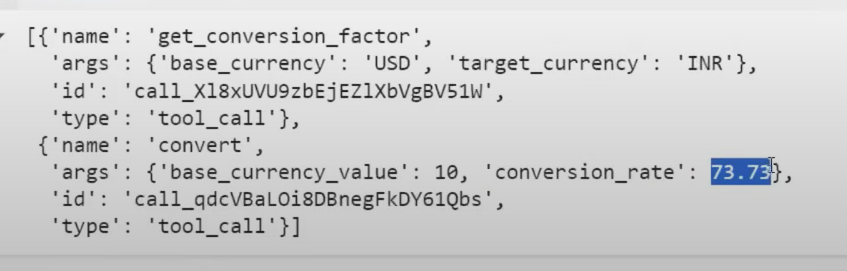

<!-- here the conversion rate is wrong , WHY SO??? model takes the conversion rate from the last time it was trained , it cant take into account of the current conversion rate as of present -->

In [14]:
# Above as u can see model decides the conversion rate by himself , the conversion rate is wrong and model takes this conversion rate from when it was last trained, so we should change the type of the conversion rate from  float to Annotated[float , InjectedToolArg]

In [15]:
# What InjectedToolArg does is , it tells the LLM that this paramter will be passed by the user later and u need not decide it by yourself

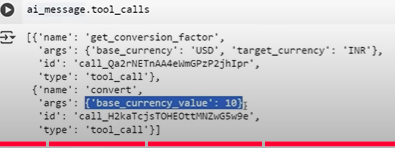

<!-- this will be the tool call once we change the type -->

In [16]:
# this will be the tool call when the type is changed 

In [ ]:
# now supply the TOOL with the tool_call

WATCH CAMPUSX 19/20 GENAI